# Lab 1 — Intro to Behavioral TV Data
Name: Anastasiia Movchaniuk | Group: КМ-43

## Setup

In [ ]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/2")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")

Using Colab cache for faster access to the 'adtech-lab1-tv-panel' dataset.


## Task 1.1 — Panel and universe

In [ ]:

print("Telecasts:", programs["telecast_id"].nunique())
print("Programs:", programs["program_name"].nunique())
print("Networks:", programs["network_code"].nunique())

households = daily_weights[daily_weights["resp_type"] == "H"]
persons = daily_weights[daily_weights["resp_type"].isin(["R", "L"])]
print("Households in panel:", households["respondent_id"].nunique() )
print("Persons in panel:", persons["respondent_id"].nunique())

household_counts = households.groupby("broadcast_date")["respondent_id"].nunique()
person_counts = persons.groupby("broadcast_date")["respondent_id"].nunique()
print("Households in-tab, average day:", round(households_counts.mean(), 1))
print("Persons in-tab, average day:", round(person_counts.mean(), 1))

household_weight = households.groupby("broadcast_date")["weight"].sum()
person_weight = persons.groupby("broadcast_date")["weight"].sum()

household_universe_m = household_weight.mean() / 1_000_000
person_universe_m = person_weight.mean() / 1_000_000
print("US TV households represented, average day (M):", f"{household_universe_m:.2f}")
print("US persons represented, average day (M):", f"{person_universe_m:.2f}")

Telecasts: 5841
Programs: 246
Networks: 10
Households in panel: 4254
Persons in panel: 10210
Households in-tab, average day: 3878.5
Persons in-tab, average day: 9268.7
US TV households represented, average day (M): 125.80
US persons represented, average day (M): 317.28


**Answer:** viewer_attributes includes participant records even if the participant has no measurement days in October. The October panel counts use daily_weights and include only participants who were in-tab on at least one day that month.

## Task 1.2 — Average audience by hour of day

,resp_type,start_ts,end_ts,weight
0,H,2024-10-01 06:00:00,2024-10-01 06:03:00,31600
1,R,2024-10-01 06:00:00,2024-10-01 06:03:00,42349
2,H,2024-10-01 06:00:00,2024-10-01 07:00:00,32395
3,R,2024-10-01 06:00:00,2024-10-01 07:00:00,40028
4,H,2024-10-01 06:01:00,2024-10-01 06:11:00,31600


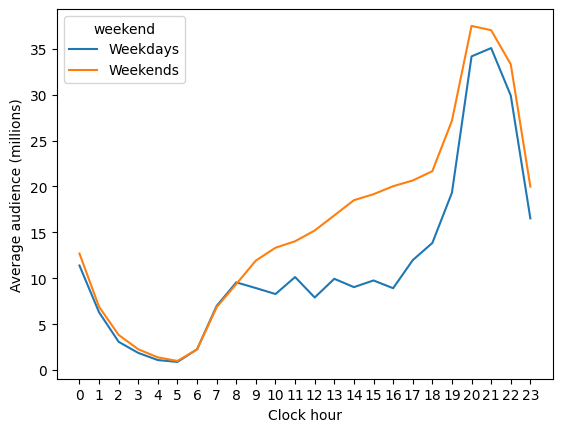

Peak hour, weekdays: 21:00
Peak hour, weekends: 20:00


In [ ]:
display(viewings[["resp_type", "start_ts", "end_ts", "weight"]].head())

sessions = viewings.loc[
    viewings["resp_type"].isin(["R", "L"]),
    ["start_ts", "end_ts", "weight" ]
].copy()

sessions["start_ts"] = pd.to_datetime(sessions["start_ts"])
sessions["end_ts"] = pd.to_datetime(sessions["end_ts"])

parts = []
while not sessions.empty:
    hour = sessions["start_ts"].dt.floor("h")
    next_hour = hour + pd.Timedelta(hours=1)
    end = sessions["end_ts"].where(sessions["end_ts"] < next_hour, next_hour)
    minutes = (end - sessions["start_ts"]).dt.total_seconds() / 60
    parts.append(pd.DataFrame({"hour": hour, "weighted_minutes": minutes * sessions["weight"]}))

    sessions = sessions.loc[end < sessions["end_ts"]].copy()
    sessions["start_ts"] = end.loc[sessions.index]

hourly = pd.concat(parts, ignore_index=True)
tv_day = (hourly["hour"] - pd.Timedelta(hours=6)).dt.normalize()
october = pd.date_range("2024-10-01", "2024-10-31")
hourly = hourly.assign(clock_hour=hourly["hour"].dt.hour, weekend=tv_day.dt.dayofweek >= 5)

totals = hourly.loc[tv_day.isin(october)].groupby(
    ["clock_hour", "weekend"]
)["weighted_minutes"].sum().unstack(fill_value=0)

days = pd.Series(october.dayofweek >= 5).value_counts()
audience = totals.div(days, axis="columns") / 60 / 1_000_000
audience = audience.rename(columns={False: "Weekdays", True: "Weekends"})

audience.plot(xlabel="Clock hour", ylabel="Average audience (millions)", xticks=range(24))
plt.show()
# plot: projected average audience (M) by clock hour, weekday vs weekend
print("Peak hour, weekdays:", f"{audience['Weekdays'].idxmax():02d}:00")
print("Peak hour, weekends:", f"{audience['Weekends'].idxmax():02d}:00")

**Answer:** The average audience peaked at 21:00 on weekdays and at 20:00 on weekends. The weekend peak was slightly higher, at about 38 million viewers compared with about 35 million on weekdays. The weekend audience was also noticeably larger in the afternoon, especially from 14:00 to 18:00.


## Task 1.3 — Session length

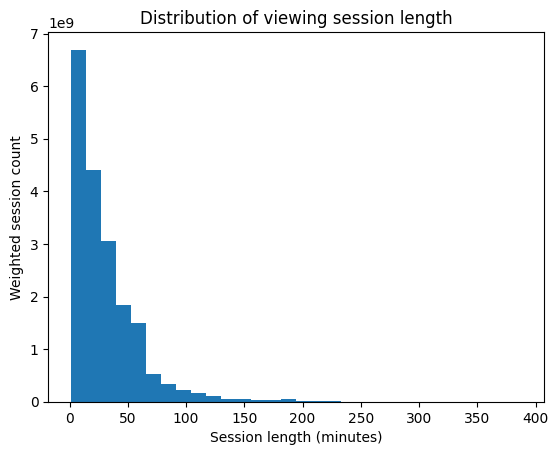

Session length, weighted mean (min): 29.4
Session length, weighted median (min): 21.0


In [ ]:
person_sessions = viewings.loc[
    viewings["resp_type"].isin(["R", "L"]),
    ["start_ts", "end_ts", "weight" ]
].copy()

start = pd.to_datetime(person_sessions["start_ts"])
end = pd.to_datetime(person_sessions["end_ts"])
person_sessions["minutes"] = (end - start).dt.total_seconds() / 60

total_weight = person_sessions["weight"].sum()
weighted_mean = (
    person_sessions["minutes"] * person_sessions["weight"]
).sum() / total_weight

ordered = person_sessions.sort_values("minutes")
running_weight = ordered["weight"].cumsum()
weighted_median = ordered.loc[
    running_weight >= total_weight / 2, "minutes"
].iloc[0]

plt.hist(
    person_sessions["minutes"],
    bins=30,
    weights=person_sessions["weight"],
)
plt.xlabel("Session length (minutes)")
plt.ylabel("Weighted session count")
plt.title("Distribution of viewing session length")
plt.show()

print("Session length, weighted mean (min):", round(weighted_mean, 1))
print("Session length, weighted median (min):", round(weighted_median, 1))


**Answer:** The weighted mean session length was 29.4 minutes, and the weighted median was 21.0 minutes. The histogram has a long right tail because a small proportion of sessions lasted much longer than most. These long sessions pull the mean upward. I would show the client the weighted median of 21 minutes because it better represents a typical viewing session.

## Task 2 — Program reach curve

,Telecast ID,Date,Household rating (%),P2+ rating (%),Projected audience (M)
0,1003837,2024-10-01,3.5,1.7,5.28
1,1003857,2024-10-02,3.1,1.5,4.68
2,1003877,2024-10-03,3.0,1.5,4.68
3,1003896,2024-10-04,3.0,1.5,4.81
4,1003936,2024-10-07,3.1,1.5,4.83
5,1003952,2024-10-08,3.2,1.6,4.97
6,1003970,2024-10-09,3.0,1.5,4.70
7,1003985,2024-10-10,3.4,1.6,5.13
8,1004001,2024-10-11,3.1,1.5,4.69
9,1004040,2024-10-14,2.9,1.4,4.59


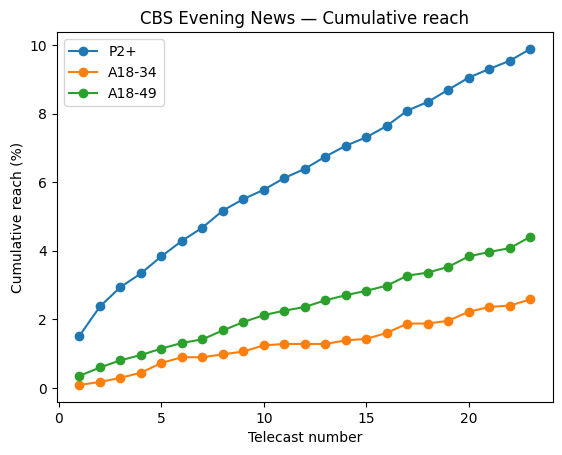

Telecasts of the program: 23
Average household rating (%): 3.2
Average P2+ rating (%): 1.6
Average projected audience (M): 4.93
Final reach P2+ (%): 9.9
Final reach A18-34 (%): 2.6
Final reach A18-49 (%): 4.4


In [ ]:

news = programs.loc[
    (programs["network_code"] == "CBS")
    & (programs["program_name"] == "CBS Evening News")
].copy()

news["broadcast_date"] = pd.to_datetime(news["broadcast_date"]).dt.normalize()
news["start_ts"] = pd.to_datetime(news["start_ts"])
news["end_ts"] = pd.to_datetime(news["end_ts"])

news = news.loc[
    news["broadcast_date"].between("2024-10-01", "2024-10-31")
].sort_values("start_ts")


cbs_sessions = viewings.loc[
    (viewings["network_code"] == "CBS")
    & viewings["resp_type"].isin(["H", "R", "L"]),
    ["respondent_id", "start_ts", "end_ts"],
].copy()

cbs_sessions["start_ts"] = pd.to_datetime(cbs_sessions["start_ts"])
cbs_sessions["end_ts"] = pd.to_datetime(cbs_sessions["end_ts"])


october_weights = daily_weights.loc[
    daily_weights["resp_type"].isin(["H", "R", "L"])
].copy()
october_weights["broadcast_date"] = pd.to_datetime(
    october_weights["broadcast_date"]
).dt.normalize()
october_weights = october_weights.loc[
    october_weights["broadcast_date"].between("2024-10-01", "2024-10-31")
]

# table: household rating, P2+ rating, projected audience (M) per telecast
rating_rows = []
viewers_by_telecast = {}

for episode in news.itertuples(index=False):

    overlap = cbs_sessions.loc[
        (cbs_sessions["start_ts"] < episode.end_ts)
        & (cbs_sessions["end_ts"] > episode.start_ts)
    ].copy()


    overlap_start = overlap["start_ts"].clip(lower=episode.start_ts)
    overlap_end = overlap["end_ts"].clip(upper=episode.end_ts)
    overlap["minutes"] = (overlap_end - overlap_start).dt.total_seconds() / 60


    minutes_by_id = overlap.groupby("respondent_id")["minutes"].sum()
    watched_ids = minutes_by_id[minutes_by_id >= 1].index


    day_weights = october_weights.loc[
        october_weights["broadcast_date"] == episode.broadcast_date
    ]
    day_households = day_weights.loc[day_weights["resp_type"] == "H"]
    day_persons = day_weights.loc[day_weights["resp_type"].isin(["R", "L"])]

    watched_households = day_households.loc[
        day_households["respondent_id"].isin(watched_ids)
    ]
    watched_persons = day_persons.loc[
        day_persons["respondent_id"].isin(watched_ids)
    ]

    household_audience = watched_households["weight"].sum()
    person_audience = watched_persons["weight"].sum()


    viewers_by_telecast[episode.telecast_id] = set(watched_persons["respondent_id"])

    rating_rows.append({
        "Telecast ID": episode.telecast_id,
        "Date": episode.broadcast_date.date(),
        "Household rating (%)": 100 * household_audience / day_households["weight"].sum(),
        "P2+ rating (%)": 100 * person_audience / day_persons["weight"].sum(),
        "Projected audience (M)": person_audience / 1_000_000,
    })

ratings = pd.DataFrame(rating_rows)
display(ratings.style.format({
    "Household rating (%)": "{:.1f}",
    "P2+ rating (%)": "{:.1f}",
    "Projected audience (M)": "{:.2f}",
}))

# plot: cumulative reach P2+, A18-34, A18-49

person_days = october_weights.loc[october_weights["resp_type"].isin(["R", "L"])]
monthly_weights = person_days.groupby("respondent_id")["weight"].mean()


ages = viewer_attributes.loc[
    viewer_attributes["attr_id"] == 300, ["respondent_id", "value"]
].set_index("respondent_id")["value"]

panel = monthly_weights.to_frame("monthly_weight").join(ages.rename("age"))

group_weights = {
    "P2+": panel["monthly_weight"],
    "A18-34": panel.loc[panel["age"].between(18, 34), "monthly_weight"],
    "A18-49": panel.loc[panel["age"].between(18, 49), "monthly_weight"],
}

seen = set()
reach_rows = []

for telecast_id in news["telecast_id"]:

    seen.update(viewers_by_telecast[telecast_id])

    row = {}
    for group, weights in group_weights.items():
        reached_weight = weights.loc[weights.index.isin(seen)].sum()
        row[group] = 100 * reached_weight / weights.sum()

    reach_rows.append(row)

reach = pd.DataFrame(reach_rows, index=range(1, len(news) + 1))
reach.plot(marker="o", xlabel="Telecast number", ylabel="Cumulative reach (%)")
plt.title("CBS Evening News — Cumulative reach")
plt.show()

print("Telecasts of the program:", len(news))
print("Average household rating (%):", f"{ratings['Household rating (%)'].mean():.1f}")
print("Average P2+ rating (%):", f"{ratings['P2+ rating (%)'].mean():.1f}")
print("Average projected audience (M):", f"{ratings['Projected audience (M)'].mean():.2f}")
print("Final reach P2+ (%):", f"{reach['P2+'].iloc[-1]:.1f}")
print("Final reach A18-34 (%):", f"{reach['A18-34'].iloc[-1]:.1f}")
print("Final reach A18-49 (%):", f"{reach['A18-49'].iloc[-1]:.1f}")

**Answer:** CBS Evening News averaged 4.93 million viewers per telecast, with a household rating of 3.2% and a P2+ rating of 1.6%. The P2+ rating stayed between 1.3% and 1.8%, while cumulative reach grew as later telecasts added viewers who had not watched earlier ones. Final reach was highest among P2+ viewers at 9.9%, followed by adults aged 18–49 at 4.4% and adults aged 18–34 at 2.6%. This is consistent with evening news reaching a smaller share of younger viewers than of the overall audience.

## Task 3 — Program frequency

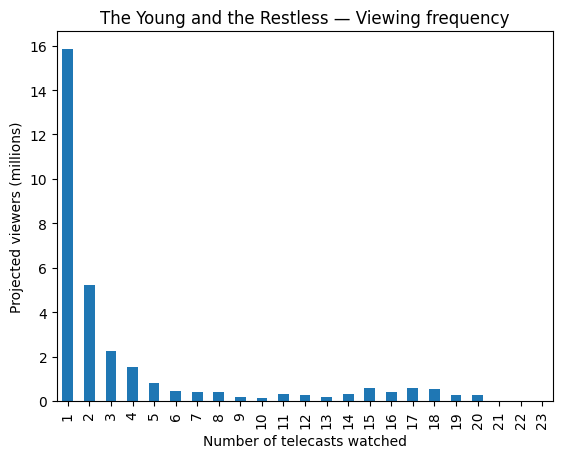

Projected viewers (M): 30.80
Average frequency (weighted): 3.6
Median frequency (weighted): 1
Share of views from the most loyal viewers: 0.704


In [ ]:

soap = programs.loc[
    (programs["network_code"] == "CBS")
    & programs["program_name"].str.casefold().eq("the young and the restless")
].copy()

soap["broadcast_date"] = pd.to_datetime(soap["broadcast_date"]).dt.normalize()
soap = soap.loc[soap["broadcast_date"].between("2024-10-01", "2024-10-31")]


watched_episodes = []

for episode in soap.itertuples(index=False):
    start = pd.Timestamp(episode.start_ts)
    end = pd.Timestamp(episode.end_ts)


    overlap = cbs_sessions.loc[
        (cbs_sessions["start_ts"] < end)
        & (cbs_sessions["end_ts"] > start)
    ]


    overlap_start = overlap["start_ts"].clip(lower=start)
    overlap_end = overlap["end_ts"].clip(upper=end)
    minutes = (overlap_end - overlap_start).dt.total_seconds() / 60
    minutes_by_id = minutes.groupby(overlap["respondent_id"]).sum()


    day_person_ids = person_days.loc[
        person_days["broadcast_date"] == episode.broadcast_date, "respondent_id"
    ]
    watched_ids = minutes_by_id[minutes_by_id >= 1].index.intersection(day_person_ids)

    for person_id in watched_ids:
        watched_episodes.append({
            "respondent_id": person_id,
            "telecast_id": episode.telecast_id,
        })

# 3. Считаем разные выпуски по каждому зрителю и добавляем его месячный вес.
episode_views = pd.DataFrame(
    watched_episodes, columns=["respondent_id", "telecast_id"]
)
frequency = (
    episode_views.groupby("respondent_id")["telecast_id"]
    .nunique()
    .to_frame("frequency")
    .join(monthly_weights.rename("weight"))
)


total_viewer_weight = frequency["weight"].sum()
weighted_views = frequency["frequency"] * frequency["weight"]
average_frequency = weighted_views.sum() / total_viewer_weight

ordered = frequency.sort_values("frequency")
running_share = ordered["weight"].cumsum() / total_viewer_weight
median_frequency = ordered.loc[running_share >= 0.50, "frequency"].iloc[0]
loyal_cutoff = ordered.loc[running_share >= 0.80, "frequency"].iloc[0]

loyal = frequency["frequency"] >= loyal_cutoff
loyal_view_share = weighted_views.loc[loyal].sum() / weighted_views.sum()

# plot: projected viewers (M) by number of telecasts watched
viewers_by_frequency = frequency.groupby("frequency")["weight"].sum() / 1_000_000
viewers_by_frequency = viewers_by_frequency.reindex(
    range(1, len(soap) + 1), fill_value=0
)

viewers_by_frequency.plot(
    kind="bar",
    xlabel="Number of telecasts watched",
    ylabel="Projected viewers (millions)",
    title="The Young and the Restless — Viewing frequency",
)
plt.show()

print("Projected viewers (M):", f"{total_viewer_weight / 1_000_000:.2f}")
print("Average frequency (weighted):", f"{average_frequency:.1f}")
print("Median frequency (weighted):", median_frequency)
print("Share of views from the most loyal viewers:", f"{loyal_view_share:.3f}")

**Answer:** The program reached an estimated 30.80 million viewers. The weighted mean was 3.6 telecasts, while the weighted median was 1. More than half of the viewers watched only one telecast. Frequent viewers pulled the mean upward, and the most loyal viewers accounted for 70.4% of weighted views. The median better describes a typical viewer.

## Task 4 — Networks by age and gender

In [ ]:

network_views = viewings.loc[
    viewings["resp_type"].isin(["R", "L"]),
    ["respondent_id", "network_code", "start_ts", "end_ts", "weight"],
].copy()

start = pd.to_datetime(network_views["start_ts"])
end = pd.to_datetime(network_views["end_ts"])
network_views["minutes"] = (end - start).dt.total_seconds() / 60
network_views["weighted_minutes"] = network_views["minutes"] * network_views["weight"]

ages = viewer_attributes.loc[
    viewer_attributes["attr_id"] == 300, ["respondent_id", "value"]
].rename(columns={"value": "age"})

sex = viewer_attributes.loc[
    viewer_attributes["attr_id"].isin([201, 202]),
    ["respondent_id", "attr_id"],
].copy()
sex["sex"] = sex["attr_id"].map({201: "M", 202: "W"})

network_views = network_views.merge(ages, on="respondent_id", how="left")
network_views = network_views.merge(
    sex[["respondent_id", "sex"]], on="respondent_id", how="left"
)


network_views["age_group"] = pd.cut(
    network_views["age"],
    bins=[18, 35, 55, float("inf")],
    labels=["18-34", "35-54", "55+"],
    right=False,
)
network_views["audience_group"] = (
    network_views["sex"].astype("string")
    + network_views["age_group"].astype("string")
)

# six top-5 tables (projected minutes): M18-34, W18-34, M35-54, W35-54, M55+, W55+
for group in ["M18-34", "W18-34", "M35-54", "W35-54", "M55+", "W55+"]:
    group_views = network_views.loc[network_views["audience_group"] == group]
    top5 = group_views.groupby("network_code")["weighted_minutes"].sum().nlargest(5)

    print(group)
    display(top5.rename("Projected viewing minutes").to_frame())

# table: 18-34 share of minutes per network, weighted and raw
minute_columns = ["minutes", "weighted_minutes"]

all_minutes = network_views.groupby("network_code")[minute_columns].sum()

young_views = network_views.loc[network_views["age"].between(18, 34)]
young_minutes = young_views.groupby("network_code")[minute_columns].sum()
young_minutes = young_minutes.reindex(all_minutes.index, fill_value=0)

shares = (young_minutes / all_minutes).rename(columns={
    "minutes": "Raw share",
    "weighted_minutes": "Weighted share",
})
shares = shares.sort_values("Weighted share", ascending=False)

display(shares[["Weighted share", "Raw share"]].style.format("{:.3f}"))

print("Youngest network:", shares["Weighted share"].idxmax())
print("Oldest network:", shares["Weighted share"].idxmin())

M18-34


,Projected viewing minutes
network_code,
FOX,4.386650e+09
NBC,3.910388e+09
CBS,3.044350e+09
ABC,3.010781e+09
FX,1.473963e+09


W18-34


,Projected viewing minutes
network_code,
FOX,4.574441e+09
NBC,4.527593e+09
ABC,3.504858e+09
CBS,2.811222e+09
FX,1.383466e+09


M35-54


,Projected viewing minutes
network_code,
FOX,1.280467e+10
NBC,1.098668e+10
ABC,9.037002e+09
CBS,8.134069e+09
FX,2.370803e+09


... (4 outputs left out)

W55+


,Projected viewing minutes
network_code,
CBS,4.712032e+10
NBC,4.139187e+10
ABC,3.884001e+10
FOX,3.691472e+10
FNC,3.145073e+10


,Weighted share,Raw share
network_code,,
FX,0.266,0.232
BRAVO,0.148,0.127
FOX,0.082,0.075
FOOD,0.078,0.071
NBC,0.073,0.068
ABC,0.064,0.060
HGTV,0.058,0.052
CBS,0.051,0.050
HIST,0.048,0.044


Youngest network: FX
Oldest network: FNC


**Answer:** FX had the highest weighted share of viewing minutes from adults aged 18–34, while FNC had the lowest. The raw share uses the minutes recorded in the panel. The weighted share adjusts those minutes based on how many people each panel member represents. Using raw figures for a client report could overstate or understate the contribution of younger viewers.

**Bonus answer:** I would look for specific programs or time slots on FNC that reach adults aged 18–34. If the data showed that those slots deliver enough young viewers for the campaign, I would recommend buying ads in those slots.